In [20]:
#Imports

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [2]:
data = pd.read_csv('/content/winequality-red.csv')
data

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5


In [3]:
data.isnull().sum()

,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


In [4]:
data.shape

(1599, 12)

In [6]:
data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [8]:
#Input and Output

x = data.drop('quality', axis= 1)
y = data['quality']

In [12]:
#Train_test_split

x_train,x_test,y_train,y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [13]:
#Train Model
model = RandomForestClassifier()
model.fit(x_train,y_train)

RandomForestClassifier()

In [15]:
#Predict
y_pred = model.predict(x_test)
print(y_pred)

[6 6 5 6 5 5 5 5 5 8 5 5 5 6 5 6 6 5 7 6 6 6 6 6 5 6 6 6 6 5 5 5 6 6 8 5 5
 6 5 6 5 5 5 6 6 7 6 6 5 5 5 6 5 6 6 5 5 5 5 6 6 6 6 6 6 5 6 5 5 6 7 6 6 6
 6 6 6 6 5 6 5 5 6 5 5 5 6 6 7 5 5 5 6 7 5 6 5 5 6 5 7 6 7 7 6 6 6 7 7 6 5
 5 5 5 5 6 5 5 6 6 6 6 6 6 6 6 7 5 5 6 5 5 5 7 6 6 5 6 5 6 5 6 5 5 5 7 5 6
 5 6 6 5 5 6 5 5 5 5 7 6 6 5 5 6 5 6 5 6 5 6 6 5 5 7 7 5 6 5 6 7 5 5 6 5 5
 5 6 5 5 6 6 5 5 5 6 7 6 5 5 5 6 5 6 5 6 5 6 6 7 6 5 5 5 6 7 5 5 5 5 6 6 4
 5 5 5 6 6 6 7 6 6 5 7 7 5 6 5 6 6 5 5 5 5 6 5 6 7 7 6 6 5 5 5 5 6 6 5 6 6
 6 6 6 6 5 6 6 5 6 5 6 5 6 6 6 5 6 6 5 6 5 6 6 5 6 7 6 6 5 6 5 5 6 5 5 5 5
 5 5 5 7 5 5 5 5 5 6 5 5 7 7 6 5 5 6 5 6 5 6 6 5]


In [16]:
#Actual V/S Prediction

comparison = pd.DataFrame({
    'Actual Value ' : y_test,
    'Predicted Value' : y_pred
})

comparison

,Actual Value,Predicted Value
963,6,6
475,5,6
1,5,5
329,5,6
149,6,5
...,...,...
1173,6,6
827,5,5
356,5,6
1287,5,6


In [19]:
#Model Evaluation

#Accuracy Score
Accuracy = accuracy_score(y_test,y_pred)

#confsion Metrics
Cm = confusion_matrix(y_test,y_pred)

#Classification Report
cr = classification_report(y_test,y_pred)


print(Accuracy)
print(Cm)
print(cr)

0.665625
[[  0   1   1   0   0   0]
 [  0   0   9   2   0   0]
 [  0   0 103  32   1   0]
 [  0   0  34  88   6   0]
 [  0   0   2  16  21   1]
 [  0   0   0   1   1   1]]
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.69      0.76      0.72       136
           6       0.63      0.69      0.66       128
           7       0.72      0.53      0.61        40
           8       0.50      0.33      0.40         3

    accuracy                           0.67       320
   macro avg       0.42      0.38      0.40       320
weighted avg       0.64      0.67      0.65       320



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


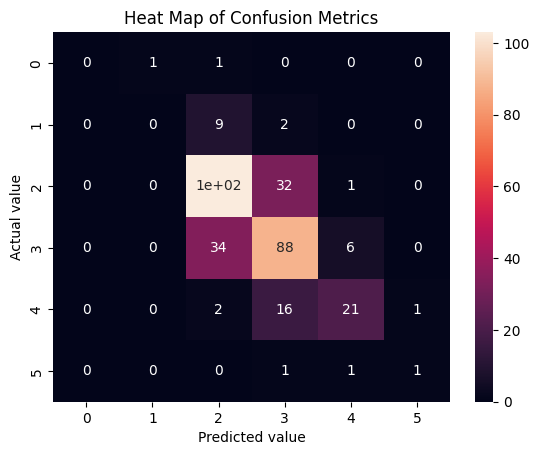

In [22]:
#heatMap

sns.heatmap(Cm, annot=True)
plt.title("Heat Map of Confusion Metrics")
plt.xlabel('Predicted value')
plt.ylabel('Actual value')
plt.show()

In [28]:
fixed_acidity = float(input("Enter fixed acidity: "))
volatile_acidity = float(input("Enter volatile acidity: "))
citric_acid = float(input("Enter citric acid: "))
residual_sugar = float(input("Enter residual sugar: "))
chlorides = float(input("Enter chlorides: "))
free_sulfur_dioxide = float(input("Enter free sulfur dioxide: "))
total_sulfur_dioxide = float(input("Enter total sulfur dioxide: "))
density = float(input("Enter density: "))
pH = float(input("Enter pH: "))
sulphates = float(input("Enter sulphates: "))
alcohol = float(input("Enter alcohol: "))

INPUT_VALUES = pd.DataFrame([[fixed_acidity,volatile_acidity,citric_acid,residual_sugar,  chlorides,free_sulfur_dioxide,total_sulfur_dioxide, density,  pH,sulphates,alcohol]],columns=x.columns)
prediction = model.predict(INPUT_VALUES)

print("The Quality of wine was Found to be : ", prediction)


Enter fixed acidity: 3
Enter volatile acidity: 4
Enter citric acid: 3
Enter residual sugar: 4
Enter chlorides: 5
Enter free sulfur dioxide: 6
Enter total sulfur dioxide: 4
Enter density: 3
Enter pH: 5
Enter sulphates: 4
Enter alcohol: 3
The Quality of wine was Found to be :  [5]
